# Mini-Project 1: Weather Forecast with Python Web APIs

This notebook compares `urllib` and `requests`, retrieves a local daily forecast from Open-Meteo, and keeps the parsing and retry logic in `src/weather.py`. The sample JSON in `tests/fixtures/` is a genuine API response captured on 14 October 2026 and makes the display work offline.

Before using MET Norway, replace the placeholder email in the configuration cell with your own university email. No contact details are invented here.

The standard-library `pathlib` and `unittest.mock` imports below are used only to locate saved samples and simulate a network outage.

## Part A: HTTP approaches

`urllib` makes the request and encoding steps explicit using `urlencode`; HTTP errors arrive as exceptions and headers are read from the response. `requests` accepts `params`, exposes elapsed time and headers directly, and has a convenient `raise_for_status()` method. Both approaches need a timeout and explicit exception handling. The `requests` call below uses the same bounded retry wrapper as the reusable client.

In [7]:
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import Request, urlopen
import json
import sys
import time
from unittest.mock import Mock

import matplotlib.pyplot as plt
import requests

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.weather import (
    GEOCODING_URL, FORECAST_URL, WeatherAPIError, choose_location,
    forecast_frame, geocode, get_forecast, get_met_forecast, request_json,
    request_response,
)

LOCATION = "Dresden"
LOCATION_CHOICE = 0
DAYS = 3
REQUEST_TIMEOUT = 10
CONTACT_EMAIL = "YOUR_UNIVERSITY_EMAIL@example.edu"  # Replace before using live APIs

In [8]:
HAS_CONTACT_EMAIL = "@" in CONTACT_EMAIL and "example.edu" not in CONTACT_EMAIL


def urllib_geocode(name: str, retries: int = 2) -> tuple[dict, int, str | None]:
    """Geocode with urllib, a timeout, HTTP checking, and bounded retries."""
    url = GEOCODING_URL + "?" + urlencode({"name": name, "count": 10, "language": "en", "format": "json"})
    headers = {"User-Agent": f"OOPWeatherAssignment/1.0 {CONTACT_EMAIL}"}
    request = Request(url, headers=headers)
    for attempt in range(retries + 1):
        try:
            with urlopen(request, timeout=REQUEST_TIMEOUT) as response:
                if response.status >= 400:
                    raise WeatherAPIError(f"HTTP request failed ({response.status})")
                return json.load(response), response.status, response.headers.get("Content-Type")
        except Exception as error:
            status = getattr(error, "code", None)
            if attempt == retries or (status is not None and status < 500):
                raise WeatherAPIError(f"urllib request failed ({status or error})") from error
            time.sleep(0.25 * (2 ** attempt))
    raise WeatherAPIError("urllib request failed after retries")

request_session = requests.Session()
if HAS_CONTACT_EMAIL:
    request_session.headers.update({"User-Agent": f"OOPWeatherAssignment/1.0 {CONTACT_EMAIL}"})

urllib_data = None
requests_data = None
if not HAS_CONTACT_EMAIL:
    print("Live requests skipped; replace CONTACT_EMAIL with your real university email to enable them.")
else:
    try:
        urllib_data, urllib_status, urllib_content_type = urllib_geocode(LOCATION)
        print(f"urllib: HTTP {urllib_status}; {urllib_content_type}; {len(urllib_data.get('results', []))} candidate(s)")
    except WeatherAPIError as error:
        print(f"urllib request unavailable: {error}")
    try:
        response = request_response(
            request_session, GEOCODING_URL,
            params={"name": LOCATION, "count": 10, "language": "en", "format": "json"},
            timeout=REQUEST_TIMEOUT,
        )
        requests_data = response.json()
        print(f"requests: HTTP {response.status_code}; {response.headers.get('Content-Type')}; {response.elapsed.total_seconds():.3f} s")
    except WeatherAPIError as error:
        print(f"requests call unavailable: {error}")

Live requests skipped; replace CONTACT_EMAIL with your real university email to enable them.


## Part B: Forecast and display

All matching candidates are listed below. Change `LOCATION_CHOICE` in the configuration cell to select an ambiguous match; the notebook never pauses for interactive input, so Restart & Run All remains reproducible. Coordinates are sent only to the selected forecast provider.

In [9]:
ROOT = Path.cwd()
if not (ROOT / "tests").exists():
    ROOT = ROOT.parent
FIXTURES = ROOT / "tests" / "fixtures"

candidates = (requests_data or {}).get("results", []) if isinstance(requests_data, dict) else []
if not candidates and HAS_CONTACT_EMAIL:
    try:
        candidates = geocode(LOCATION, session=request_session)
    except WeatherAPIError as error:
        print(f"Live geocoding unavailable: {error}")
if not candidates:
    candidates = json.loads((FIXTURES / "geocoding.json").read_text(encoding="utf-8")).get("results", [])
    print("Using the saved Dresden geocoding sample.")

for index, candidate in enumerate(candidates):
    print(f"{index}: {candidate.get('name')}, {candidate.get('admin1', '')}, {candidate.get('country', '')} ({candidate.get('latitude')}, {candidate.get('longitude')})")
location = choose_location(candidates, LOCATION_CHOICE)

if HAS_CONTACT_EMAIL:
    try:
        forecast_json = get_forecast(location["latitude"], location["longitude"], DAYS, session=request_session)
        print("Forecast source: Open-Meteo live API.")
    except (WeatherAPIError, ValueError) as error:
        forecast_json = json.loads((FIXTURES / "weather_forecast.json").read_text(encoding="utf-8"))
        print(f"Live forecast unavailable ({error}); using the saved response captured 14 October 2026.")
else:
    forecast_json = json.loads((FIXTURES / "weather_forecast.json").read_text(encoding="utf-8"))
    print("Using the saved forecast response captured 14 October 2026.")

forecast = forecast_frame(forecast_json)
print(f"{location.get('name')}: {len(forecast)} forecast day(s), timezone {forecast_json.get('timezone', 'local')}")
print(forecast.to_string(index=False))
print("Data: Open-Meteo Forecast API; weather descriptions use its WMO code table.")

Using the saved Dresden geocoding sample.
0: Dresden, Saxony, Germany (51.05089, 13.73832)
Using the saved forecast response captured 14 October 2026.
Dresden: 3 forecast day(s), timezone Europe/Berlin
      date  max_temp_c  min_temp_c  precipitation_mm  max_wind_kmh  weather_code             weather
2026-10-14        16.4         9.8               0.1          11.3            80 Slight rain showers
2026-10-15        16.6         6.2               0.0           4.1             3            Overcast
2026-10-16        19.6         6.8               0.0           7.1             3            Overcast
Data: Open-Meteo Forecast API; weather descriptions use its WMO code table.


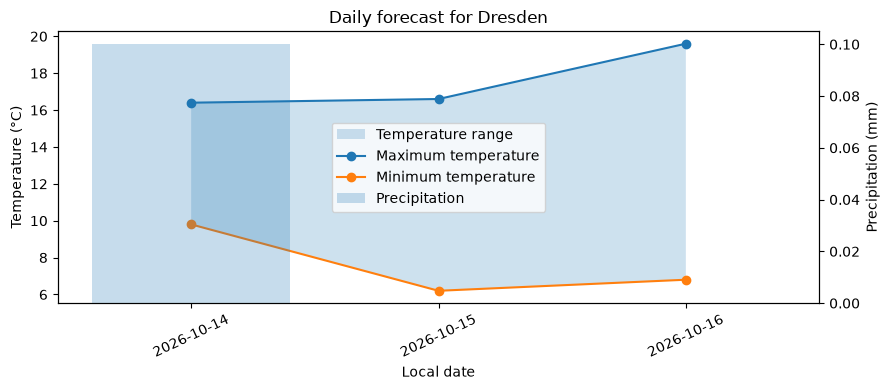

Forecast range: 6.2–19.6 °C; total precipitation: 0.1 mm.
Weather data by Open-Meteo.com (CC BY 4.0).


In [10]:
fig, temperature_axis = plt.subplots(figsize=(9, 4))
temperature_axis.fill_between(forecast["date"], forecast["min_temp_c"], forecast["max_temp_c"], alpha=0.22, label="Temperature range")
temperature_axis.plot(forecast["date"], forecast["max_temp_c"], marker="o", label="Maximum temperature")
temperature_axis.plot(forecast["date"], forecast["min_temp_c"], marker="o", label="Minimum temperature")
temperature_axis.set(xlabel="Local date", ylabel="Temperature (°C)", title=f"Daily forecast for {location.get('name')}")
temperature_axis.tick_params(axis="x", rotation=25)
precipitation_axis = temperature_axis.twinx()
precipitation_axis.bar(forecast["date"], forecast["precipitation_mm"], alpha=0.25, color="tab:blue", label="Precipitation")
precipitation_axis.set_ylabel("Precipitation (mm)")
lines, labels = temperature_axis.get_legend_handles_labels()
other_lines, other_labels = precipitation_axis.get_legend_handles_labels()
temperature_axis.legend(lines + other_lines, labels + other_labels, loc="best")
fig.tight_layout()
plt.show()
print(f"Forecast range: {forecast['min_temp_c'].min():.1f}–{forecast['max_temp_c'].max():.1f} °C; total precipitation: {forecast['precipitation_mm'].sum():.1f} mm.")
print("Weather data by Open-Meteo.com (CC BY 4.0).")

## Part C: Failure demonstrations

The live invalid-city and tiny-timeout examples are caught so offline or slow networks do not stop the notebook. Simulated connection loss is fully offline. Retry sleeps are bounded and only transient request or server failures are retried; client-side HTTP errors are returned immediately.

In [11]:
if HAS_CONTACT_EMAIL:
    try:
        invalid_candidates = geocode("ThisCityDoesNotExist_20261014", session=request_session)
        print(f"Invalid city: {len(invalid_candidates)} candidate(s); empty results are handled.")
    except WeatherAPIError as error:
        print(f"Invalid-city request also handled an unavailable network: {error}")
else:
    print("Invalid city: no candidates is handled by geocode; live demonstration skipped until a real email is configured.")

try:
    get_forecast(95, 0, DAYS)
except ValueError as error:
    print(f"Invalid latitude: {error}")

offline_session = Mock()
offline_session.get.side_effect = requests.ConnectionError("simulated offline")
try:
    request_json(offline_session, GEOCODING_URL, retries=1, backoff=0)
except WeatherAPIError as error:
    print(f"Simulated no network: {error}")

timeout_session = requests.Session() if HAS_CONTACT_EMAIL else Mock()
if not HAS_CONTACT_EMAIL:
    timeout_session.get.side_effect = requests.Timeout("simulated tiny timeout")
try:
    request_json(
        timeout_session, GEOCODING_URL, params={"name": LOCATION},
        timeout=0.000001, retries=0, backoff=0,
    )
    print("The tiny-timeout request completed unusually quickly.")
except WeatherAPIError as error:
    print(f"Tiny timeout handled: {error}")

Invalid city: no candidates is handled by geocode; live demonstration skipped until a real email is configured.
Invalid latitude: Latitude must be -90..90 and longitude -180..180
Simulated no network: Weather request failed: simulated offline
Tiny timeout handled: Weather request failed: simulated tiny timeout


In [12]:
if "example.edu" in CONTACT_EMAIL or "YOUR_UNIVERSITY_EMAIL" in CONTACT_EMAIL:
    print("MET Norway comparison skipped: enter your real university email in the configuration cell first.")
else:
    try:
        met_json = get_met_forecast(
            location["latitude"], location["longitude"], CONTACT_EMAIL,
            session=request_session,
        )
        print("MET Norway locationforecast retrieved; source: https://api.met.no/weatherapi/locationforecast/2.0")
        print(f"Returned top-level fields: {list(met_json)}")
    except (WeatherAPIError, ValueError) as error:
        print(f"MET Norway request unavailable: {error}")

MET Norway comparison skipped: enter your real university email in the configuration cell first.


## Part D: Report

### Data flow

The notebook takes a city name from one configuration cell. The first request resolves that name to one or more candidate places. The student checks the displayed names, regions, countries, and coordinates, then chooses the candidate index in the same configuration cell. The selected latitude and longitude go to the forecast service; its daily JSON arrays become a labeled table, a short summary, and a chart. The flow keeps user choice explicit while allowing Restart & Run All without an input prompt.

```mermaid
flowchart LR
  A[Configuration: city and choice] --> B[Open-Meteo geocoding]
  B --> C[Candidate list and selected coordinates]
  C --> D[Open-Meteo forecast request]
  D --> E[Validate daily JSON and decode WMO codes]
  E --> F[Table, summary, and chart]
  G[Saved response fixtures] -. offline fallback .-> E
```

### Requests and parsing

Part A makes the same geocoding query using two HTTP styles. The `urllib` version calls `urlencode` to construct the query string and passes a timeout to `urlopen`. The `requests` version passes a `params` mapping and uses the shared `request_response` function. That wrapper calls `raise_for_status`, sets a timeout, limits retries, and exponentially increases the delay after transient failures. The response also exposes its HTTP status, content type, and elapsed time, which makes the request inspectable rather than treating returned JSON as proof of success. Both approaches are small for one request; `requests` gives more convenient response and exception handling, while the standard library avoids an external HTTP dependency and makes encoding explicit.

The reusable `geocode` function returns an empty list when Open-Meteo omits the `results` key. When a query matches several places, the notebook lists the candidate names and regions. The configured index chooses one without stopping for a prompt, satisfying the reproducibility requirement and making the choice auditable. `get_forecast` validates coordinate bounds and the requested day count before making a request. It requests daily maximum and minimum temperature, precipitation total, maximum wind speed, and the WMO weather code, using `timezone=auto` so forecast dates follow local time. `forecast_frame` checks that daily fields exist and have equal lengths before constructing the table. The code mapping follows the WMO interpretation used by Open-Meteo.

The figure overlays the daily minimum-to-maximum temperature range with precipitation bars on a second labeled axis. The printed summary gives the temperature range and total forecast precipitation. Units appear in column names and axis labels, and the output credits Open-Meteo. For an offline run, the notebook loads captured JSON fixtures only if a live call fails. The fixtures are saved in the repository and the automated parsing checks read them directly; they are not presented as a current forecast.

### Licensing and usage

Open-Meteo provides the geocoding and forecast endpoints used for the main result. Its API-data license is Creative Commons Attribution 4.0 International (CC BY 4.0). A user may share or adapt those data, but must credit the source, link the license, and identify modifications. This notebook links and names the provider beside its output. Open-Meteo's free API is intended for non-commercial use and has request limits; its terms describe caps of 10,000 requests a day, 5,000 an hour, and 600 a minute. A student exercise is non-commercial, but an advertised, subscription, or otherwise commercial product should not assume the free service is permitted. Such a product should review the paid API terms or select a service whose commercial license fits. The provider also disclaims guarantees of accuracy, completeness, availability, or suitability. A production application therefore needs a freshness policy, alternate provider or cached result, and user-facing uncertainty rather than treating an API response as guaranteed truth. Open-Meteo's terms and license were checked on 14 October 2026; operators should recheck them before deployment because online terms can change.

MET Norway's Locationforecast is an optional second source, not a drop-in confirmation of identical values: forecasts can differ because products, models, update times, and represented locations differ. MET's open data are generally offered under the Norwegian Licence for Open Government Data 2.0 and CC BY 4.0 unless a product says otherwise. Users should credit MET Norway and link the downloadable source where practical. The service requires an identifying, truthful User-Agent with a contact route, recommends caching, and restricts excessive request rates; its service has no delivery guarantee or SLA. The notebook will not invent an email. It skips the request until the student supplies a real university email. Coordinates are rounded to four decimal places for this endpoint. A real product would also check for deprecated API versions, honor cache headers, and avoid polling more often than the forecast changes. MET terms were checked on 14 October 2026.

### Reliability

Weather services depend on the network, DNS, provider capacity, and valid response formats. A city may have no match; a common name may have many. The implementation distinguishes an empty result from a failed request and prints the candidates rather than silently selecting an arbitrary place. Requests have finite timeouts. Connection exceptions and server errors can be retried twice with exponential backoff; ordinary client errors are not retried because the same invalid request is unlikely to improve. Every successful `requests` response passes `raise_for_status`, and failures become a readable `WeatherAPIError` after the retry cap. An invalid latitude is rejected locally. The no-network case uses a mocked connection failure, while a very small live timeout demonstrates a real timeout without allowing it to abort the notebook. The live invalid-city request is also guarded, so the demonstration remains runnable when internet access is absent.

Retries cannot fix a provider outage, malformed JSON, or a bad query, and repeated requests can burden a public service. The retry count and wait are therefore deliberately small. Parsing checks require the data the display needs and consistent array lengths, which turns an unexpected schema change into a useful error. Offline tests use saved provider responses and do not require network access. A normal run tries the live forecast first, then transparently labels the saved response as an offline fallback. This is suitable for coursework, not a promise of production uptime: a deployed service would additionally cache responses according to provider headers, monitor failures, validate freshness, and avoid repeated requests from every client. Weather is inherently forecast rather than observed data, so even a technically successful response can be uncertain.

### Privacy

Geocoding sends the typed place name to Open-Meteo. The forecast request sends latitude and longitude. These are necessary for the service to find the place and forecast it, but they disclose location intent to a third party. A city-level forecast usually reveals less than a street address, so this assignment asks for a city rather than a precise home or device location. Even a place name can be sensitive if it describes a clinic, shelter, workplace, or a person's routine. Do not put names, account identifiers, or other personal details into a location query. A real mobile product should explain the transfer, request location only when needed, minimize precision, and use a server-side proxy if direct client requests would expose users' IP addresses. A proxy is not an automatic privacy solution: it shifts responsibility to the operator, who must limit logs, secure them, and set deletion rules.

Open-Meteo's free-service terms say technical logs can include IP addresses and coordinates and that individual logs are deleted after 90 days. MET Norway says direct API access can place a user's IP and requested coordinates in its logs, stored in Oslo; its terms recommend a proxy when anonymity is needed. The email in MET's User-Agent identifies the application maintainer and should be a real contact address, not a fabricated identity. These practices illustrate data minimization: request only the forecast fields and precision needed, make few calls, avoid keeping raw queries, and disclose the providers. The notebook stores only public sample weather JSON, not a user's private location history. Students should still avoid committing sensitive location inputs or personal contact information to a public repository.

### Limits and sources

This report describes a teaching client, not a safety-critical forecast product. Weather models change and a daily summary hides hourly variation. The two providers may differ, and neither guarantees that forecasts are correct or always available. The notebook displays the source and local timezone so a reader can interpret the dates, but it does not make a recommendation for travel or emergency response. The most important design choices are visible failure, bounded traffic, source attribution, minimal location precision, and an offline parser test.

Sources checked 14 October 2026: [Open-Meteo API documentation](https://open-meteo.com/en/docs), [Open-Meteo Geocoding documentation](https://open-meteo.com/en/docs/geocoding-api), [Open-Meteo license](https://open-meteo.com/en/licence), [Open-Meteo terms and privacy](https://open-meteo.com/en/terms), [MET Norway Locationforecast](https://api.met.no/weatherapi/locationforecast/2.0/documentation), [MET Norway terms](https://api.met.no/doc/TermsOfService), and [MET Norway licensing](https://api.met.no/doc/License).